# Red neuronal para clasificar círculos
Red neuronal con PyTorch (2 entradas → 4 neuronas ocultas con sigmoide → 1 salida) que separa dos clases en forma de círculos concéntricos.
Resultado: pérdida de 0.715 a 0.0016 en 1000 épocas y 100 % de exactitud en entrenamiento.

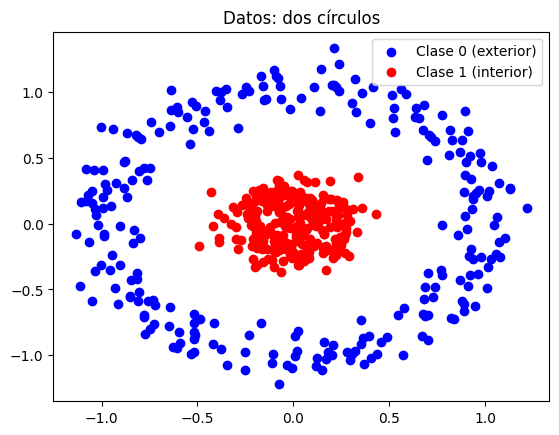

In [1]:
import torch                          # PyTorch: tensores y redes neuronales
import torch.nn as nn                 # capas (Linear), funciones de pérdida, etc.
import numpy as np                    # arreglos numéricos (para la cuadrícula del gráfico)
import matplotlib.pyplot as plt       # gráficas
from sklearn import datasets          # generador de datasets de prueba

# ---------- 1. DATOS ----------
n_pts = 500                           # número de puntos
X_np, y_np = datasets.make_circles(   # dos círculos, uno dentro del otro
    n_samples=n_pts,                  # 500 puntos en total
    random_state=123,                 # semilla: siempre salen los mismos puntos
    noise=0.1,                        # ruido: mueve un poco cada punto al azar
    factor=0.2)                       # el círculo interior mide 20 % del exterior
x_data = torch.tensor(X_np, dtype=torch.float32)                 # entradas (500, 2): coordenadas x1, x2
y_data = torch.tensor(y_np, dtype=torch.float32).reshape(-1, 1)  # etiquetas (500, 1); -1 = "calcula tú el tamaño"

def scatter_plot():                   # dibuja los puntos del dataset
    plt.scatter(X_np[y_np == 0, 0], X_np[y_np == 0, 1], color='blue', label='Clase 0 (exterior)')  # scatter: un punto por fila
    plt.scatter(X_np[y_np == 1, 0], X_np[y_np == 1, 1], color='red', label='Clase 1 (interior)')   # filtra solo la clase 1
    plt.legend()                      # muestra la leyenda con los label

scatter_plot()                        # dibuja los datos antes de entrenar
plt.title('Datos: dos círculos')      # título de la gráfica
plt.show()                            # muestra la gráfica

In [2]:
# ---------- 2. MODELO ----------
class Model(nn.Module):               # nuestra red hereda de nn.Module
    def __init__(self, input_size, H1, output_size):
        super().__init__()                          # inicializa la parte interna de nn.Module
        self.linear = nn.Linear(input_size, H1)     # capa oculta: 2 entradas → H1 neuronas (cada una hace w·x + b)
        self.linear2 = nn.Linear(H1, output_size)   # capa de salida: H1 → 1 neurona
    def forward(self, x):                           # el "paso 1: predecir" de tu práctica
        x = torch.sigmoid(self.linear(x))           # capa oculta + sigmoide (la parte no lineal)
        x = torch.sigmoid(self.linear2(x))          # salida entre 0 y 1 = probabilidad de ser clase 1
        return x
    def predict(self, x):                           # convierte la probabilidad en 0 o 1
        with torch.no_grad():                       # solo predecimos: no hace falta calcular gradientes
            return (self.forward(x) >= 0.5).int()   # 1 si prob ≥ 0.5; sirve para 1 punto o para 500

torch.manual_seed(2)                  # semilla: los pesos iniciales siempre son los mismos
model = Model(2, 4, 1)                # 2 entradas, 4 neuronas ocultas, 1 salida
print("Parámetros:", sum(p.numel() for p in model.parameters()))  # cuenta todos los pesos y sesgos (debe dar 17)

Parámetros: 17


epoch: 0 loss: 0.7149
epoch: 100 loss: 0.0714
epoch: 200 loss: 0.0171
epoch: 300 loss: 0.0096
epoch: 400 loss: 0.0063
epoch: 500 loss: 0.0045
epoch: 600 loss: 0.0034
epoch: 700 loss: 0.0027
epoch: 800 loss: 0.0022
epoch: 900 loss: 0.0019


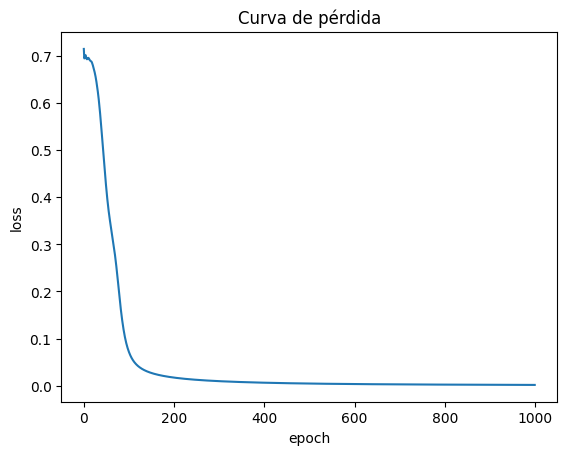

Exactitud en entrenamiento: 1.0


In [3]:
# ---------- 3. ENTRENAMIENTO ----------
criterion = nn.BCELoss()              # pérdida para clasificación binaria (en regresión usábamos el ECM)
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)  # Adam: versión mejorada de w := w − α·dw
epochs = 1000                         # número de vueltas completas sobre los datos
losses = []                           # aquí guardamos la pérdida de cada vuelta (como historial_J)
for i in range(epochs):
    y_pred = model(x_data)            # 1. predecir (model(x) llama a forward por ti)
    loss = criterion(y_pred, y_data)  # 2. calcular la pérdida
    losses.append(loss.item())        # .item() saca el número del tensor
    optimizer.zero_grad()             # 3. borrar los gradientes de la vuelta anterior
    loss.backward()                   # 4. calcular todas las derivadas (los dw y db de cada peso)
    optimizer.step()                  # 5. actualizar todos los pesos
    if i % 100 == 0:                  # imprime solo cada 100 vueltas, no las 1000
        print("epoch:", i, "loss:", round(loss.item(), 4))

plt.plot(range(epochs), losses)       # curva de la pérdida: debe bajar y aplanarse
plt.xlabel('epoch')                   # eje x: número de vuelta
plt.ylabel('loss')                    # eje y: pérdida
plt.title('Curva de pérdida')         # título de la gráfica
plt.show()                            # muestra la gráfica

exactitud = (model.predict(x_data) == y_data).float().mean().item()  # % de puntos bien clasificados
print("Exactitud en entrenamiento:", exactitud)

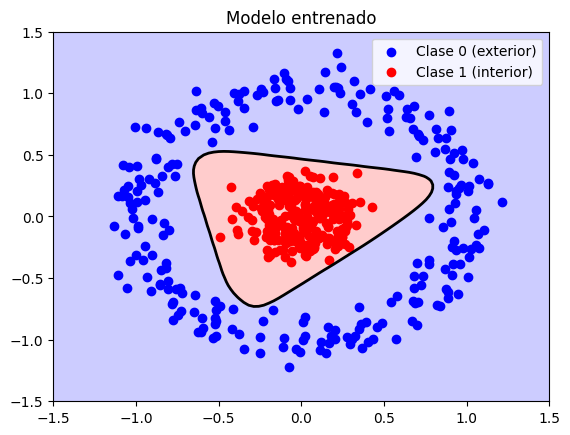

In [4]:
# ---------- 4. FRONTERA DE DECISIÓN ----------
def plot_decision_boundary(model, title):
    x_span = np.linspace(-1.5, 1.5, 100)               # 100 valores de x1
    y_span = np.linspace(-1.5, 1.5, 100)               # 100 valores de x2
    xx, yy = np.meshgrid(x_span, y_span)               # cuadrícula de 100 × 100 puntos
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)  # la cuadrícula como (10000, 2)
    with torch.no_grad():                              # solo predecimos
        z = model(grid).reshape(xx.shape).numpy()      # probabilidad en cada punto, de vuelta a 100 × 100
    plt.contourf(xx, yy, z, levels=[0, 0.5, 1], alpha=0.2, colors=['blue', 'red'])  # colorea la zona de cada clase
    plt.contour(xx, yy, z, levels=[0.5], colors='black', linewidths=2)            # línea negra = frontera (prob = 0.5)
    scatter_plot()                                     # encima, los puntos reales
    plt.title(title)                                   # título de la gráfica
    plt.show()                                         # muestra la gráfica

plot_decision_boundary(model, 'Modelo entrenado')      # llama a la función con el modelo ya entrenado

In [5]:
# ---------- 5. PREDECIR UN PUNTO NUEVO ----------
punto = torch.tensor([[0.025, 0.025]])                # doble corchete: forma (1, 2), un punto con 2 coordenadas
print("Predicción:", model.predict(punto).item())     # 1 = círculo interior, 0 = exterior

Predicción: 1
